# Hafta 9 · Evrişimli Sinir Ağları (CNN)

**Yapay Zekâya Giriş — Laboratuvar Defteri**  
Dr. Seda Bayat Toksöz · Iğdır Üniversitesi · 2026–2027 Güz

Bu defterde önce evrişim ve havuzlama katmanlarının çıktı boyutlarını ve parametre sayılarını ders notlarındaki elle hesaplarla karşılaştırıyoruz; ardından scikit-learn'ün yerleşik 8×8 rakam verisiyle küçük bir CNN eğitip öğrenilen filtreleri ve öznitelik haritalarını görselleştiriyoruz. İnternetten veri indirmeye gerek yoktur.

Hücreleri yukarıdan aşağıya sırayla çalıştırın (**Shift + Enter**). Parametreleri değiştirip sonucun nasıl değiştiğini gözlemleyin.

In [1]:
# Grafik ayarları (ders notlarıyla aynı renk paleti)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]),
})

### Yardımcı fonksiyon
Görüntüleri ve öznitelik haritalarını ızgara hâlinde çizmek için.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def goster(goruntuler, basliklar, sutun=4, cmap="gray", boyut=3):
    """Görüntüleri ızgara hâlinde çizer."""
    satir = -(-len(goruntuler) // sutun)
    fig, eksen = plt.subplots(satir, sutun, squeeze=False,
                              figsize=(boyut * sutun, boyut * 0.9 * satir))
    for ax in eksen.ravel():
        ax.axis("off")
    for ax, g, b in zip(eksen.ravel(), goruntuler, basliklar):
        ax.imshow(np.asarray(g), cmap=cmap)
        ax.set_title(b)
    plt.tight_layout()
    plt.show()

## 1. Bir evrişim katmanı ne görür? (Şekil 9.2)
Dört elle seçilmiş 3×3 filtre bir kedi görüntüsüne uygulanıyor. Gerçek bir CNN'de bu filtreler eğitimle öğrenilir.

(1, 1, 180, 200) (1, 4, 178, 198) (1, 4, 89, 99)


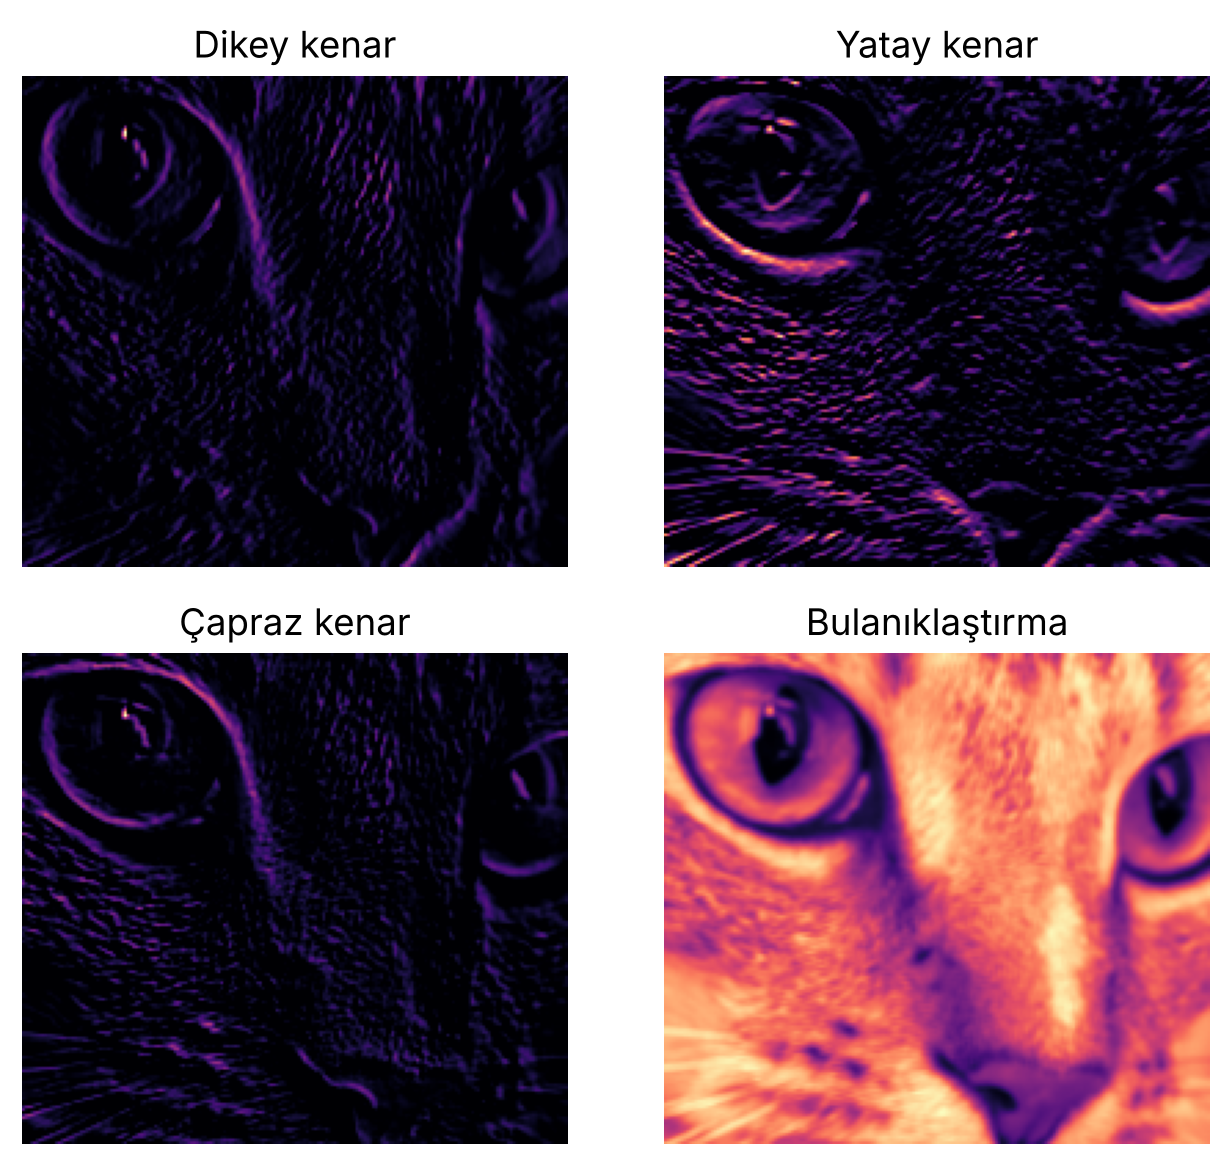

In [3]:
import torch
import torch.nn.functional as F
from skimage import data

gri = data.chelsea().mean(axis=2)[80:260, 130:330] / 255
x = torch.tensor(gri, dtype=torch.float32)[None, None]
K = torch.tensor([[[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],  # dikey
                  [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],  # yatay
                  [[0, 1, 2], [-1, 0, 1], [-2, -1, 0]],  # çapraz
                  [[1, 1, 1], [1, 1, 1], [1, 1, 1]]])    # bulanık
K = K.float()[:, None]
K[3] /= 9                          # ortalama filtresi
harita = F.relu(F.conv2d(x, K))    # evrişim + ReLU
havuz = F.max_pool2d(harita, 2)    # 2x2 maks. havuzlama
print(tuple(x.shape), tuple(harita.shape), tuple(havuz.shape))

goster(harita[0], ["Dikey kenar", "Yatay kenar", "Çapraz kenar",
                   "Bulanıklaştırma"], sutun=2, cmap="magma")

## 2. Çıktı boyutu ve parametre sayısı (Çözümlü Örnek 9.2 ve 9.3)

In [4]:
from torch import nn

# Çözümlü Örnek 9.2: 32x32x3 girdi, 6 filtre 5x5
x = torch.randn(1, 3, 32, 32)
for P, S in [(0, 1), (2, 1), (2, 2)]:
    conv = nn.Conv2d(3, 6, kernel_size=5, padding=P, stride=S)
    print(f"P={P}, S={S} ->", tuple(conv(x).shape[1:]))
print("parametre:", sum(p.numel() for p in conv.parameters()))

# Çözümlü Örnek 9.3: evrişim mi, tam bağlı mı?
conv = nn.Conv2d(3, 64, kernel_size=3)
tam = nn.Linear(224 * 224 * 3, 64)
for ad, m in [("evrişim", conv), ("tam bağlı", tam)]:
    print(ad, sum(p.numel() for p in m.parameters()))

P=0, S=1 -> (6, 28, 28)
P=2, S=1 -> (6, 32, 32)
P=2, S=2 -> (6, 16, 16)
parametre: 456


evrişim 1792
tam bağlı 9633856


## 3. Havuzlama ve çok kanallı evrişim (Çözümlü Örnek 9.4 ve 9.1)

In [5]:
# Çözümlü Örnek 9.4: 2x2 pencere, adım 2
A = torch.tensor([[1., 3, 2, 1], [4, 6, 5, 0],
                  [3, 1, 1, 2], [7, 2, 0, 4]])[None, None]
print(F.max_pool2d(A, 2)[0, 0])
print(F.avg_pool2d(A, 2)[0, 0])

# Çözümlü Örnek 9.1: iki kanallı girdi, 2x2x2 filtre, bias 1
X = torch.tensor([[[1., 2, 0], [0, 1, 3], [2, 1, 0]],
                  [[0., 1, 1], [2, 0, 1], [1, 2, 2]]])
K = torch.tensor([[[1., 0], [0, -1]],
                  [[0., 1], [1, 0]]])
O = F.conv2d(X[None], K[None], bias=torch.tensor([1.]))
print(O[0, 0])

tensor([[6., 5.],
        [7., 4.]])
tensor([[3.5000, 2.0000],
        [3.2500, 1.7500]])
tensor([[4., 1.],
        [1., 5.]])


## 4. LeNet-5'i katman katman çözümlemek (Çözümlü Örnek 9.5)

In [6]:
lenet = nn.Sequential(
    nn.Conv2d(1, 6, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(6, 16, 5), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(400, 120), nn.ReLU(),
    nn.Linear(120, 84), nn.ReLU(),
    nn.Linear(84, 10),
)
h = torch.zeros(1, 1, 28, 28)        # tek bir 28x28 gri görüntü
for k in lenet:
    h = k(h)
    n = sum(p.numel() for p in k.parameters())
    if not isinstance(k, nn.ReLU):   # ReLU satırlarını atla
        ad, boyut = type(k).__name__, tuple(h.shape[1:])
        print(f"{ad:<10}{str(boyut):<13}{n:>6}")
print("toplam:", sum(p.numel() for p in lenet.parameters()))

Conv2d    (6, 28, 28)     156
MaxPool2d (6, 14, 14)       0
Conv2d    (16, 10, 10)   2416
MaxPool2d (16, 5, 5)        0
Flatten   (400,)            0
Linear    (120,)        48120
Linear    (84,)         10164
Linear    (10,)           850
toplam: 61706


## 5. PyTorch ile basit bir CNN (CIFAR-10 boyutlarında)
Notlardaki model; eğitim döngüsü 7. haftadakiyle aynıdır, yalnızca model değişir.

In [7]:
class BasitCNN(nn.Module):
    def __init__(self, sinif_sayisi=10):
        super().__init__()
        self.oznitelik = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),   # 32x32x3 -> 32x32x32
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> 16x16x32
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # -> 16x16x64
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> 8x8x64
        )
        self.siniflandirici = nn.Sequential(
            nn.Flatten(),                                 # -> 4096
            nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, sinif_sayisi),
        )

    def forward(self, x):
        return self.siniflandirici(self.oznitelik(x))

In [8]:
torch.manual_seed(0)
model = BasitCNN()
x = torch.randn(16, 3, 32, 32)    # 16 görüntülük yığın
print(model(x).shape)             # torch.Size([16, 10])
print(sum(p.numel() for p in model.parameters()))  # 545098

h = x                             # katman katman boyut
for k in list(model.oznitelik) + list(model.siniflandirici):
    h = k(h)
    n = sum(p.numel() for p in k.parameters())
    ad, boyut = type(k).__name__, tuple(h.shape)
    print(f"{ad:<10}{str(boyut):<17}{n:>7}")

torch.Size([16, 10])
545098
Conv2d    (16, 32, 32, 32)     896
ReLU      (16, 32, 32, 32)       0
MaxPool2d (16, 32, 16, 16)       0
Conv2d    (16, 64, 16, 16)   18496
ReLU      (16, 64, 16, 16)       0
MaxPool2d (16, 64, 8, 8)         0
Flatten   (16, 4096)             0
Linear    (16, 128)         524416
ReLU      (16, 128)              0
Dropout   (16, 128)              0
Linear    (16, 10)            1290


## 6. Laboratuvar: ilk CNN'imizi eğitelim
scikit-learn'ün yerleşik **8×8 el yazısı rakam** verisi (1797 örnek) internetsiz çalışır. Aynı adımlar MNIST (28×28) ve CIFAR-10 (32×32×3) için de geçerlidir; yalnızca boyutlar değişir.

eğitim: (1437, 1, 8, 8)
test  : (360, 1, 8, 8)


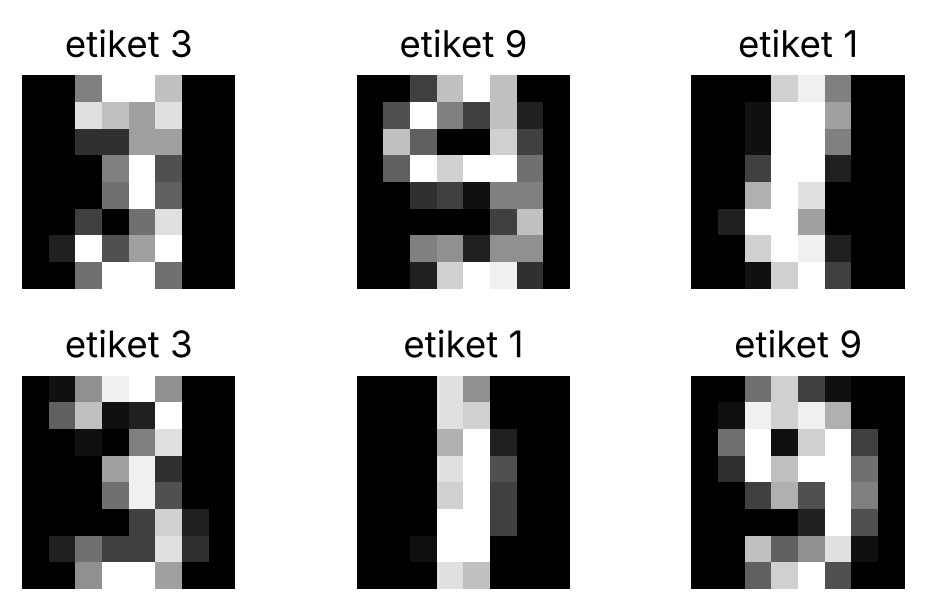

In [9]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

X, y = load_digits(return_X_y=True)       # 1797 rakam, 8x8
X = torch.tensor(X / 16, dtype=torch.float32)
X = X.view(-1, 1, 8, 8)                   # (N, C, H, W)
y = torch.tensor(y)
X_egt, X_test, y_egt, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y)
print("eğitim:", tuple(X_egt.shape))
print("test  :", tuple(X_test.shape))
goster(X_egt[:6, 0], [f"etiket {int(t)}" for t in y_egt[:6]],
       sutun=3, boyut=1.6)

### Model: iki evrişim bloğu + sınıflandırıcı
Her katmandan sonra tensörün şeklini ve katmanın parametre sayısını yazdırıyoruz.

In [10]:
torch.manual_seed(0)
model = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),   # 16x8x8
    nn.MaxPool2d(2),                             # 16x4x4
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),  # 32x4x4
    nn.MaxPool2d(2),                             # 32x2x2
    nn.Flatten(),                                # 128
    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(64, 10),                           # 10 logit
)
h = X_egt[:1]
for k in model:
    h = k(h)
    n = sum(p.numel() for p in k.parameters())
    print(f"{type(k).__name__:<10}{str(tuple(h.shape)):<16}{n:>5}")
print("toplam:", sum(p.numel() for p in model.parameters()))

Conv2d    (1, 16, 8, 8)     160
ReLU      (1, 16, 8, 8)       0
MaxPool2d (1, 16, 4, 4)       0
Conv2d    (1, 32, 4, 4)    4640
ReLU      (1, 32, 4, 4)       0
MaxPool2d (1, 32, 2, 2)       0
Flatten   (1, 128)            0
Linear    (1, 64)          8256
ReLU      (1, 64)             0
Dropout   (1, 64)             0
Linear    (1, 10)           650
toplam: 13706


### Eğitim döngüsü
7. haftadaki dört adım: ileri yayılım → kayıp → geri yayılım → güncelleme.

In [11]:
yukleyici = DataLoader(TensorDataset(X_egt, y_egt), batch_size=32, shuffle=True)
kayip_fn = nn.CrossEntropyLoss()             # softmax + çapraz entropi
opt = torch.optim.Adam(model.parameters(), lr=0.003)
for epok in range(1, 16):
    model.train(); toplam = 0                # Dropout açık
    for xb, yb in yukleyici:
        opt.zero_grad()
        kayip = kayip_fn(model(xb), yb)      # ileri yayılım + kayıp
        kayip.backward()                     # her filtre ağırlığının gradyanı
        opt.step()                           # filtreler güncellenir
        toplam += kayip.item() * len(yb)
    if epok % 3 == 0:
        model.eval()                         # Dropout kapalı
        with torch.no_grad():
            dogru = (model(X_test).argmax(1) == y_test).float().mean().item()
        print(f"epok {epok:2d} | ort. kayıp {toplam / len(X_egt):.3f} | test doğruluğu {dogru:.3f}")

epok  3 | ort. kayıp 0.492 | test doğruluğu 0.881


epok  6 | ort. kayıp 0.173 | test doğruluğu 0.939


epok  9 | ort. kayıp 0.090 | test doğruluğu 0.950


epok 12 | ort. kayıp 0.074 | test doğruluğu 0.961


epok 15 | ort. kayıp 0.040 | test doğruluğu 0.967


### Öğrenilen filtreler
İlk evrişim katmanının 16 filtresinden 8'i (her biri 3×3). Kırmızı pozitif, mavi negatif ağırlık.

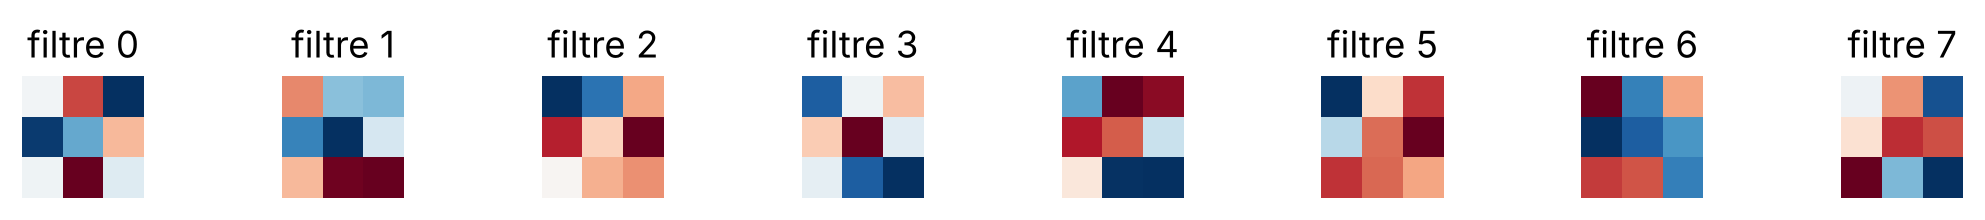

In [12]:
W = model[0].weight.detach()[:, 0]           # 16 filtre, her biri 3x3
goster(W[:8], [f"filtre {i}" for i in range(8)], sutun=8, cmap="RdBu_r", boyut=1.2)

### Bir test rakamının öznitelik haritaları (evrişim + ReLU sonrası)

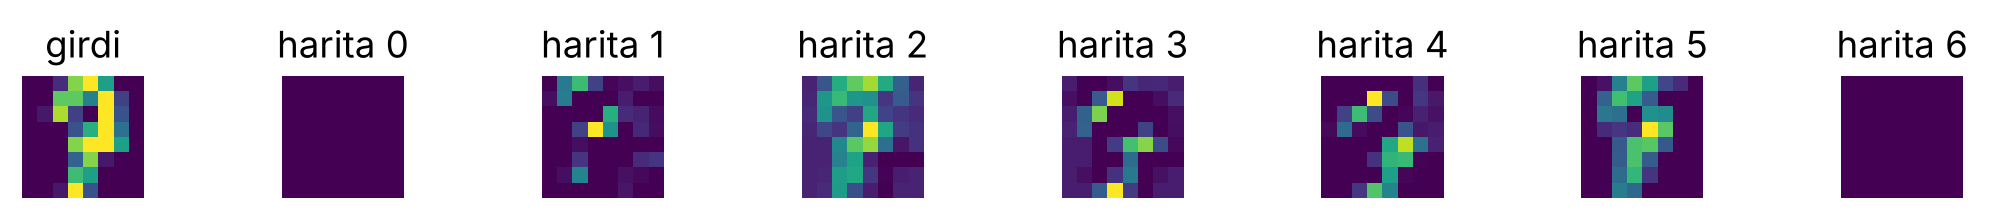

In [13]:
with torch.no_grad():
    harita = model[1](model[0](X_test[:1]))[0]   # 16 harita, her biri 8x8
goster([X_test[0, 0]] + list(harita[:7]), ["girdi"] + [f"harita {i}" for i in range(7)],
       sutun=8, cmap="viridis", boyut=1.2)

### Karışıklık matrisi
Satırlar gerçek, sütunlar tahmin edilen rakam.

In [14]:
from sklearn.metrics import confusion_matrix
model.eval()
with torch.no_grad():
    tahmin = model(X_test).argmax(1)
print(confusion_matrix(y_test, tahmin))

[[36  0  0  0  0  0  0  0  0  0]
 [ 0 34  0  0  0  0  0  0  2  0]
 [ 0  1 32  2  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 35  0  0  0  0  1]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 36  0  0  0]
 [ 0  0  0  0  1  0  0 34  0  1]
 [ 1  2  0  0  0  0  0  1 31  0]
 [ 0  0  0  0  0  0  0  0  0 36]]


### Yanlış sınıflanan örnekler (gerçek → tahmin)

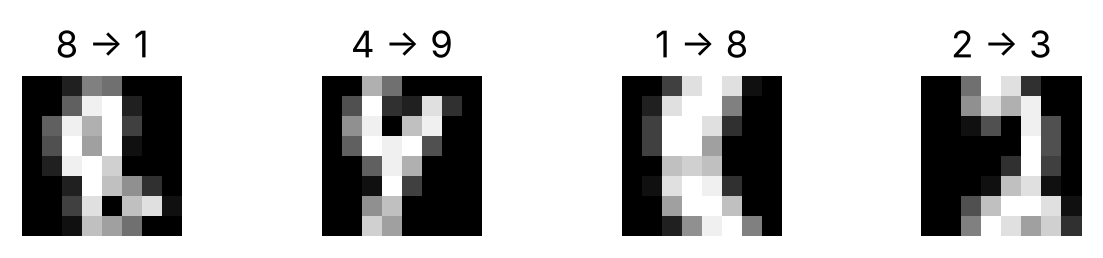

In [15]:
yanlis = (tahmin != y_test).nonzero().flatten()[:4]
baslik = [f"{int(y_test[i])} → {int(tahmin[i])}"
          for i in yanlis]
goster(X_test[yanlis, 0], baslik, sutun=4, boyut=1.4)

### Alıştırma (Değerlendirme Soruları 7, 8 ve 9)
Önce kâğıt üzerinde çözün, sonra hücreyi çalıştırıp karşılaştırın.

In [ ]:
# Soru 7: 6x6 girdi
x = torch.randn(1, 1, 6, 6)
c = nn.Conv2d(1, 1, 3)
print(tuple(c(x).shape), tuple(F.max_pool2d(c(x), 2).shape))
print(tuple(nn.Conv2d(1, 1, 3, padding=1, stride=2)(x).shape))

# Soru 8: 2x2 maksimum havuzlama
A = torch.tensor([[2., 8, 1, 0], [5, 3, 4, 9],
                  [0, 1, 6, 2], [3, 2, 7, 5]])
print(F.max_pool2d(A[None, None], 2)[0, 0])

# Soru 9: 128x128x3 girdi
ag = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.MaxPool2d(2),
                   nn.Conv2d(32, 64, 3, padding=1), nn.MaxPool2d(2))
h = torch.zeros(1, 3, 128, 128)
for k in ag:
    h = k(h)
    print(type(k).__name__, tuple(h.shape[1:]), sum(p.numel() for p in k.parameters()))